# Random Forest Trial
Sample Random Forest Classifier training and prediction on sample dataset and data points.

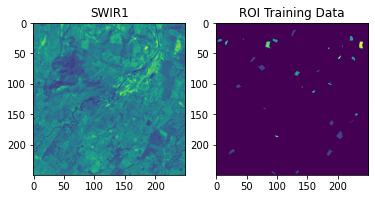

In [1]:
from osgeo import gdal, gdal_array
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Read in our image and ROI image
img_ds = gdal.Open('example/LE70220491999322EDC01_stack.gtif', gdal.GA_ReadOnly)
roi_ds = gdal.Open('example/training_data.gtif', gdal.GA_ReadOnly)

img = np.zeros((img_ds.RasterYSize, img_ds.RasterXSize, img_ds.RasterCount),
               gdal_array.GDALTypeCodeToNumericTypeCode(img_ds.GetRasterBand(1).DataType))
for b in range(img.shape[2]):
    img[:, :, b] = img_ds.GetRasterBand(b + 1).ReadAsArray()
    
roi = roi_ds.GetRasterBand(1).ReadAsArray().astype(np.uint8)

# Display them
plt.subplot(121)
plt.imshow(img[:, :, 4])
plt.title('SWIR1')

plt.subplot(122)
plt.imshow(roi)
plt.title('ROI Training Data')

plt.show()

In [2]:
from sklearn.model_selection import train_test_split

# bangalore_data_1D = bangalore_data_array.reshape(4198376,6)
# labael_bangalore_1D = labelBangalore.flatten()
features = img[roi > 0, :]
print(features.min(),features.max())
features = features[:,:7]
labels = roi[roi > 0]
print(features.shape)
print(labels.shape)


xTrain, xTest, yTrain, yTest = train_test_split(features, labels, test_size=0.4, random_state=42)


print(xTrain.shape)
print(xTest.shape)

0 4789
(718, 7)
(718,)
(430, 7)
(288, 7)


In [3]:
from sklearn.ensemble import RandomForestClassifier

# Initialize our model with 500 trees
rf = RandomForestClassifier(n_estimators=500, oob_score=True)

# Fit our model to training data
rf = rf.fit(xTrain, yTrain)

In [4]:
print('Our OOB prediction of accuracy is: {oob}%'.format(oob=rf.oob_score_ * 100))

Our OOB prediction of accuracy is: 98.13953488372093%


In [5]:
img_ds = gdal.Open('../custom_map_server/main/out2019.tif', gdal.GA_ReadOnly)
img_ds = gdal.Warp('', img_ds, width=256, height=256, format='MEM')

img = np.zeros((img_ds.RasterYSize, img_ds.RasterXSize, img_ds.RasterCount),
               gdal_array.GDALTypeCodeToNumericTypeCode(img_ds.GetRasterBand(1).DataType))
img.shape
for b in range(img.shape[2]):
    img[:, :, b] = img_ds.GetRasterBand(b + 1).ReadAsArray()

In [6]:
# Take our full image, ignore the Fmask band, and reshape into long 2d array (nrow * ncol, nband) for classification
# new_shape = (img.shape[0] * img.shape[1], img.shape[2] - 1)

img_as_array = img[:, :, :7].reshape(256*256,7)
print('Reshaped from {o} to {n}'.format(o=img.shape,
                                        n=img_as_array.shape))

# Now predict for each pixel
class_prediction = rf.predict(img_as_array)

# Reshape our classification map
class_prediction = class_prediction.reshape(img[:, :, 0].shape)
print(class_prediction.shape)

Reshaped from (256, 256, 12) to (65536, 7)
(256, 256)


In [7]:
img

array([[[   0,    0,    0, ...,    0,    0,    0],
        [   1,    2,    3, ...,   25,   11,    5],
        [ 100,  105,  164, ..., 1706,  699,  303],
        ...,
        [   0,    0,    0, ...,    0,    0,    0],
        [   0,    0,    0, ...,    0,    0,    0],
        [   0,    0,    0, ...,    0,    0,    0]],

       [[   0,    0,    0, ...,    0,    0,    0],
        [   2,    3,    3, ...,   31,   14,    6],
        [  99,  109,  156, ..., 1550,  629,  276],
        ...,
        [   0,    0,    0, ...,    0,    0,    0],
        [   0,    0,    0, ...,    0,    0,    0],
        [   0,    0,    0, ...,    0,    0,    0]],

       [[   0,    0,    0, ...,    0,    0,    0],
        [   4,    3,    4, ...,   36,   15,    7],
        [ 127,  131,  181, ..., 1678,  707,  317],
        ...,
        [   0,    0,    0, ...,    0,    0,    0],
        [   0,    0,    0, ...,    0,    0,    0],
        [   0,    0,    0, ...,    0,    0,    0]],

       ...,

       [[   0,    0,    

(256, 256)


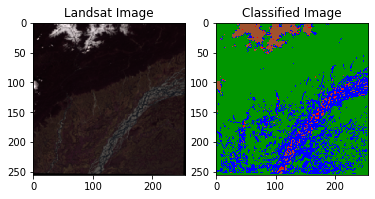

In [8]:
# Visualize

# First setup a 5-4-3 composite
def color_stretch(image, index, minmax=(0, 10000)):
    colors = image[:, :, index].astype(np.float64)

    max_val = minmax[1]
    min_val = minmax[0]

    # Enforce maximum and minimum values
    colors[colors[:, :, :] > max_val] = max_val
    colors[colors[:, :, :] < min_val] = min_val

    for b in range(colors.shape[2]):
        colors[:, :, b] = colors[:, :, b] * 1 / (max_val - min_val)
        
    return colors
    
img543 = color_stretch(img, [4, 3, 2], (0, 8000))

# See https://github.com/matplotlib/matplotlib/issues/844/
n = class_prediction.max()
# Next setup a colormap for our map
colors = dict((
    (0, (0, 0, 0, 255)),  # Nodata
    (1, (0, 150, 0, 255)),  # Forest
    (2, (0, 0, 255, 255)),  # Water
    (3, (0, 255, 0, 255)),  # Herbaceous
    (4, (160, 82, 45, 255)),  # Barren
    (5, (255, 0, 0, 255))  # Urban
))
# Put 0 - 255 as float 0 - 1
for k in colors:
    v = colors[k]
    _v = [_v / 255.0 for _v in v]
    colors[k] = _v
    
index_colors = [colors[key] if key in colors else 
                (255, 255, 255, 0) for key in range(1, n + 1)]
cmap = plt.matplotlib.colors.ListedColormap(index_colors, 'Classification', n)

# Now show the classmap next to the image
plt.subplot(121)
plt.imshow(img543)
plt.title('Landsat Image')
print(class_prediction.shape)
plt.subplot(122)
plt.imshow(class_prediction, cmap=cmap, interpolation='none')
plt.title('Classified Image')

plt.show()

## Compiler Script Testing
Checking backend compiler function for RandomForest

In [9]:
import joblib
path = '../custom_map_server/main/model1.joblib'
joblib.dump(rf, path)

['../custom_map_server/main/model1.joblib']

In [10]:
from osgeo import gdal, gdal_array
import numpy as np
from PIL import Image
import cv2
from pyproj import CRS, Transformer
from django.http import HttpResponse
from sklearn.ensemble import RandomForestClassifier
from osgeo import gdal, gdal_array
import numpy as np
from PIL import Image
import cv2
import matplotlib.pyplot as plt
from django.http import HttpResponse
import joblib
import os

In [11]:
# Compiler Scripts -- helpers and core module
def get_dataset(layer='http://mobileapp.nesdr.gov.in/out2019.tif', projWin=[10588291,3128373,10466722,3249448], coord_sys="EPSG:4326"):
    projWin = coord(projWin, coord_sys)
    dataset = gdal.Open(
        '/vsicurl/'+layer,
        #'../custom_map_server/main/out2019.tif',
        gdal.GA_ReadOnly
        )
    out = gdal.Warp('', dataset, width=256, height=256, outputBounds=projWin, format='MEM')
    return out

class B():
    def __init__(self,dataset=None, band_no=0, band=None, ip_minR=0, ip_maxR=2500):
        #print(band_no, dataset)
        if dataset is None:
            self._band = band
        else:
            self._band = norm(x=np.array(dataset.GetRasterBand(band_no).ReadAsArray()),ip_minR=ip_minR,ip_maxR=ip_maxR)
    
    @property
    def band(self):
        return self._band
    
    def __add__(self,y):
        return B(band=self._band+y.band)
    
    def __sub__(self, y):
        return B(band=self._band-y.band)
    
    def __mul__(self, y):
        if isinstance(y,B):
            return B(band=np.multiply(self._band,y.band))
        else:
            return B(band=self._band * y)
    
    def __truediv__(self, y):
        if isinstance(y,B):
            return B(band=np.divide(self._band, y.band, out=np.zeros_like(self._band), where=y.band!=0, casting="unsafe"))
        else:
            return B(band=self._band/y)

def apply_cmap(im, cmap):
    if cmap=='red':
        return np.dstack((np.zeros(im.shape),np.zeros(im.shape),im))
    elif cmap=='green':
        return np.dstack((np.zeros(im.shape),im,np.zeros(im.shape)))
    elif cmap=='blue':
        return np.dstack((im,np.zeros(im.shape),np.zeros(im.shape)))
    else:
        return im

def coord(projWin, coord_sys):
    transformer = Transformer.from_crs("EPSG:3857", coord_sys)
    projWin[1],projWin[0] = transformer.transform(projWin[0], projWin[1])
    projWin[3],projWin[2] = transformer.transform(projWin[2], projWin[3])
    return projWin

def norm(
    x, y=None, z=None,
    op_minR=0, op_maxR=1,
    op_minG=0, op_maxG=1,
    op_minB=0, op_maxB=1,
    ip_minR=0, ip_maxR=2500,
    ip_minG=0, ip_maxG=2500,
    ip_minB=0, ip_maxB=4000):
    if y is None and z is None:
        indices = np.where(x==0)
        x = (x-ip_minR)/(ip_maxR-ip_minR)
        x = ((op_maxR-op_minR)*x)+op_minR
        x[indices] = 0
        return x * 255.0
    indices1 = np.where(x==0)
    indices2 = np.where(y==0)
    indices3 = np.where(z==0)
    x = (x-ip_minB)/(ip_maxB-ip_minB)
    y = (x-ip_minG)/(ip_maxG-ip_minG)
    z = (x-ip_minR)/(ip_maxB-ip_minR)
    x = ((op_maxB-op_minB)*x)+op_minB
    y = ((op_maxG-op_minG)*y)+op_minG
    z = ((op_maxR-op_minR)*z)+op_minR
    x[indices1] = 0
    y[indices2] = 0
    z[indices3] = 0
    return x * 255.0, y * 255.0, z * 255.0

In [12]:
# Compiler Scripts -- ml module
class RandomForest(object):
    def __init__(self,saved_path=None,colors=None,**kwargs):
        if saved_path is not None:
            self.rf = joblib.load(saved_path)
        else:
            self.rf = RandomForestClassifier(**kwargs)
        self.colors = ()
        self.class_prediction = None
    
    def dump(self, path):
        joblib.dump(self.rf, path)
    
    def fit(self, X, y):
        self.rf.fit(X, y)
    
    def colormap(self, colors):
        self.colors = colors
        print(self.colors)
    
    def predict(self, img, bands, index=[4,3,2], minmax=(0,8000)):
        '''if index is not None:
            if minmax is None:
                minmax=(0,10000)
            img = color_stretch(img, index, minmax)'''
        img = img.ReadAsArray()
        img = np.moveaxis(img, 0, -1)
        img_as_array = img[:, :, :bands].reshape(-1,bands)
        self.class_prediction = self.rf.predict(img_as_array)
        self.class_prediction = self.class_prediction.reshape(img[:, :, 0].shape)
        
        return self
    
    @property
    def prediction_map(self):
        n = self.class_prediction.max()
        print(self.colors)
        for k in self.colors:
            v = self.colors[k]
            _v = [_v / 255.0 for _v in v]
            self.colors[k] = _v
        index_colors = [self.colors[key] if key in self.colors else (255, 255, 255, 0) for key in range(1, n + 1)]
        cmap = plt.matplotlib.colors.ListedColormap(index_colors, 'Classification', n)
        return B(band=self.class_prediction)

In [13]:
# Compiler Scripts -- user_func module [Modified for notebook]
def setup(
    R, G=None, B=None,
    weight=None, 
    op_minR=0, op_maxR=1, 
    op_minG=0, op_maxG=1, 
    op_minB=0, op_maxB=1,  
    ip_minR=-0.5, ip_maxR=0.8, 
    ip_minG=-0.5, ip_maxG=0.8, 
    ip_minB=-0.5, ip_maxB=0.8,
    cmap='std'
    ):
    if (np.max(R.band)==0 and G is None and B is None) or (np.max(R.band)==0 and np.max(G.band)==0 and np.max(B.band)==0):
        im = np.zeros((256,256,4))
        img = Image.fromarray(im, mode='RGBA')
        response = HttpResponse(content_type="image/png")
        img.save(response, "PNG")
        return response
    if weight is None:
        weight = [1,1,1]
    if G is None and B is None:
        im = np.array(norm(
            x = weight[0]*R.band,
            op_minR=op_minR, op_maxR=op_maxR,
            ip_minR=ip_minR, ip_maxR=ip_maxR))
        im = apply_cmap(im, cmap)
    else:
        im = np.dstack(norm(
            x=weight[0]*R.band, 
            y=weight[1]*G.band, 
            z=weight[2]*B.band,
            op_minR=op_minR, op_maxR=op_maxR,
            op_minG=op_minG, op_maxG=op_maxG,
            op_minB=op_minB, op_maxB=op_maxB,
            ip_minR=ip_minR, ip_maxR=ip_maxR,
            ip_minG=ip_minG, ip_maxG=ip_maxG,
            ip_minB=ip_minB, ip_maxB=ip_maxB))
    print(im.max(),im.min())
    return im

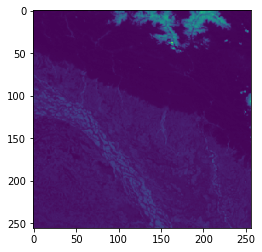

In [14]:
d = get_dataset()
plt.imshow(d.GetRasterBand(4).ReadAsArray())

In [15]:
# Sample front end script version
rf = RandomForest(saved_path='../custom_map_server/main/model1.joblib')
response = setup(
    R=rf.predict(d,7).prediction_map,
    ip_minR=1, ip_maxR=7,
)

()
170.0 0.0


In [16]:
response

array([[ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
       ...,
       [ 0. ,  0. ,  0. , ..., 42.5, 42.5, 42.5],
       [ 0. ,  0. ,  0. , ..., 42.5, 42.5, 42.5],
       [ 0. ,  0. ,  0. , ..., 42.5,  0. , 42.5]])

In [17]:
response.shape

(256, 256)

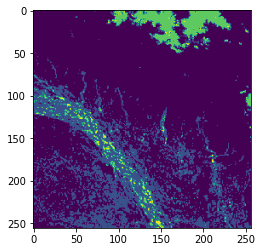

In [18]:
plt.imshow(response)